# Metadata

In [2]:
# @@PATHS@@ @@LOAD_METADATA@@ — Load CMMD series metadata and breast annotations.
from pathlib import Path
import pandas as pd

ROOT = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "data" / "cmmd").is_dir()
)
RAW = ROOT / "data" / "cmmd"
SOURCE = RAW / "The-Chinese-Mammography-Database"
OUT = RAW / "processed"

series_df = pd.read_csv(
    SOURCE / "metadata" / "metadata.csv",
    dtype={"PatientID": "string"},
)
clinical_df = pd.read_excel(
    SOURCE / "CMMD_clinicaldata_revision.xlsx",
    sheet_name="Sheet1",
    engine="openpyxl",
    dtype={"ID1": "string", "LeftRight": "string"},
)

assert series_df["SeriesInstanceUID"].is_unique, "Duplicate series identifiers"
assert not clinical_df.duplicated(["ID1", "LeftRight"]).any(), \
    "Duplicate clinical patient-side records"
assert set(series_df["PatientID"]) == set(clinical_df["ID1"]), \
    "Patient identifiers differ between imaging and clinical metadata"

print("Series metadata:", series_df.shape)
print("Clinical metadata:", clinical_df.shape)

Series metadata: (1775, 27)
Clinical metadata: (1872, 7)


In [3]:
# @@CLINICAL_POOL@@ — Attach DICOM study and series identifiers to each annotated breast.
pool = clinical_df.merge(
    series_df[["PatientID", "StudyInstanceUID", "SeriesInstanceUID"]]
        .rename(columns={"PatientID": "ID1"}),
    on="ID1",
    how="left",
    validate="many_to_one",
)

assert pool[["StudyInstanceUID", "SeriesInstanceUID"]].notna().all().all(), \
    "Clinical records without a matching DICOM study or series"

print("Clinical pool:", pool.shape)
print("Unique patients:", pool["ID1"].nunique())
print("Breast labels:", pool["classification"].value_counts().to_dict())

Clinical pool: (1872, 9)
Unique patients: 1775
Breast labels: {'Malignant': 1316, 'Benign': 556}


In [4]:
# @@IMAGE_METADATA@@ — Match DICOM views to breast annotations and build image-level metadata.
import pydicom

rows = []
for path in sorted((SOURCE / "CMMD").rglob("*.dcm")):
    dcm = pydicom.dcmread(path, stop_before_pixels=True)
    rows.append({
        "image_id": str(dcm.SOPInstanceUID),
        "ID1": dcm.PatientID,
        "LeftRight": dcm.ImageLaterality,
        "StudyInstanceUID": str(dcm.StudyInstanceUID),
        "SeriesInstanceUID": str(dcm.SeriesInstanceUID),
        "view": {
            "cranio-caudal": "CC",
            "medio-lateral oblique": "MLO",
        }[dcm.ViewCodeSequence[0].CodeMeaning.strip()],
        "dicom_path": str(path.relative_to(RAW)),
    })

images = pd.DataFrame(rows)
assert images["image_id"].is_unique, "Duplicate DICOM instance identifiers"

joined = pool.merge(
    images,
    on=["ID1", "LeftRight", "StudyInstanceUID", "SeriesInstanceUID"],
    how="left",
    validate="one_to_many",
)

assert joined["image_id"].notna().all(), \
    "Annotated breasts without matching images"
assert (
    joined.groupby(["ID1", "LeftRight"])["image_id"]
    .transform("size").eq(joined["number"]).all()
), "Image counts differ from clinical annotations"
assert not joined.duplicated(["ID1", "LeftRight", "view"]).any(), \
    "Repeated projection for an annotated breast"

df = pd.DataFrame({
    "image_id": joined["image_id"],
    "patient_id": joined["ID1"],
    "target": joined["classification"].map({"Benign": 0, "Malignant": 1}).astype("int8"),
    "age": joined["Age"],
    "abnormality": joined["abnormality"],
    "laterality": joined["LeftRight"],
    "view": joined["view"],
    "source_cohort": joined["ID1"].str.split("-").str[0],
    "dicom_path": joined["dicom_path"],
})

print("Image metadata:", df.shape, "| prevalence:", round(df["target"].mean(), 4))
print("Images without clinical annotations:", len(images) - len(df))

Image metadata: (3744, 9) | prevalence: 0.703
Images without clinical annotations: 1458


In [5]:
# @@SPLIT@@ — Exclude audited duplicate patients and create patient-disjoint train/test sets.
from sklearn.model_selection import StratifiedGroupKFold

EXCLUDED_PATIENTS = {"D1-0202", "D1-0808", "D1-1292", "D2-0284"}
eligible_df = df.loc[~df["patient_id"].isin(EXCLUDED_PATIENTS)].reset_index(drop=True)

splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_idx, test_idx = next(
    splitter.split(
        eligible_df,
        y=eligible_df["target"],
        groups=eligible_df["patient_id"],
    )
)

train_df = eligible_df.iloc[train_idx].reset_index(drop=True)
test_df = eligible_df.iloc[test_idx].reset_index(drop=True)

assert set(train_df["patient_id"]).isdisjoint(test_df["patient_id"]), \
    "Patient leakage between train and test"
assert train_df["target"].nunique() == test_df["target"].nunique() == 2, \
    "Both target classes must be present in each split"

print("Excluded patients:", sorted(EXCLUDED_PATIENTS))
print("Excluded annotated images:", len(df) - len(eligible_df))

for name, frame in (("Train", train_df), ("Test", test_df)):
    print(
        f"{name}: {len(frame)} images | "
        f"{frame['patient_id'].nunique()} patients | "
        f"prevalence: {frame['target'].mean():.4f}"
    )

Excluded patients: ['D1-0202', 'D1-0808', 'D1-1292', 'D2-0284']
Excluded annotated images: 10
Train: 2986 images | 1416 patients | prevalence: 0.7033
Test: 748 images | 355 patients | prevalence: 0.7032


In [ ]:
overlap = set(train_df["patient_id"]) & set(test_df["patient_id"])
assert len(overlap) == 0, f"Patient leakage detected: {len(overlap)} patients overlap"

overlap = set(train_df["image_id"]) & set(test_df["image_id"])
assert len(overlap) == 0, f"Data leakage detected: {len(overlap)} images overlap"

print("Train samples:", len(train_df))
print("Test samples:", len(test_df))

print("\nTrain target distribution:")
print(train_df["target"].value_counts(normalize=True))

print("\nTest target distribution:")
print(test_df["target"].value_counts(normalize=True))

Train samples: 2986
Test samples: 748

Train target distribution:
target
1    0.703282
0    0.296718
Name: proportion, dtype: float64

Test target distribution:
target
1    0.703209
0    0.296791
Name: proportion, dtype: float64


In [7]:
OUT.mkdir(parents=True, exist_ok=True)

train_df.to_parquet(OUT / "train-metadata.parquet", index=False, engine="pyarrow")
test_df.to_parquet(OUT / "test-metadata.parquet", index=False, engine="pyarrow")

print("Saved:", OUT / "train-metadata.parquet")
print("Saved:", OUT / "test-metadata.parquet")

Saved: /mnt/disk1/home/cgiovannoni/mod-attendance/data/cmmd/processed/train-metadata.parquet
Saved: /mnt/disk1/home/cgiovannoni/mod-attendance/data/cmmd/processed/test-metadata.parquet


## Images

In [8]:
# @@IMAGE_CONVERSION@@ — Convert CMMD DICOM pixels to native-resolution 8-bit grayscale PNG bytes.
import io
import numpy as np
import pydicom
from PIL import Image


def dicom_to_png_bytes(image_path):
    dcm = pydicom.dcmread(image_path)

    assert dcm.PhotometricInterpretation == "MONOCHROME2" and dcm.PixelRepresentation == 0, \
        "Expected unsigned MONOCHROME2 pixels"
    assert dcm.BitsStored in (8, 16), "Expected 8-bit or 16-bit pixels"
    assert float(dcm.RescaleSlope) == 1 and float(dcm.RescaleIntercept) == 0, \
        "Unexpected DICOM rescaling"

    pixels = np.rint(
        dcm.pixel_array.astype(np.float32) * (255.0 / ((1 << dcm.BitsStored) - 1))
    ).astype(np.uint8)

    buffer = io.BytesIO()
    Image.fromarray(pixels).save(buffer, format="PNG")
    return buffer.getvalue()

In [9]:
# @@WRITE_HDF5@@ — Store converted CMMD images as PNG bytes keyed by image_id.
import h5py
from tqdm import tqdm

for split, frame in (("train", train_df), ("test", test_df)):
    output_path = RAW / f"{split}-image.hdf5"

    with h5py.File(output_path, "w") as h5:
        h5.attrs["format"] = "png_bytes"
        h5.attrs["image_size"] = str((1914, 2294))
        h5.attrs["id_col"] = "image_id"

        for row in tqdm(
            frame[["image_id", "dicom_path"]].itertuples(index=False),
            total=len(frame),
            desc=f"Writing {split} images",
        ):
            h5.create_dataset(
                row.image_id,
                data=np.bytes_(dicom_to_png_bytes(RAW / row.dicom_path)),
            )

        assert set(h5.keys()) == set(frame["image_id"]), \
            f"{split}: HDF5 keys differ from metadata identifiers"

    print("Saved:", output_path, "| images:", len(frame))

Writing train images: 100%|██████████| 2986/2986 [06:21<00:00,  7.83it/s]


Saved: /mnt/disk1/home/cgiovannoni/mod-attendance/data/cmmd/train-image.hdf5 | images: 2986


Writing test images: 100%|██████████| 748/748 [01:35<00:00,  7.80it/s]

Saved: /mnt/disk1/home/cgiovannoni/mod-attendance/data/cmmd/test-image.hdf5 | images: 748


Checking train images:   0%|          | 0/2986 [00:00<?, ?it/s]

Checking train images: 100%|██████████| 2986/2986 [02:13<00:00, 22.40it/s]

train: 2986 images verified | preview: D1-0070, L, MLO, target=1


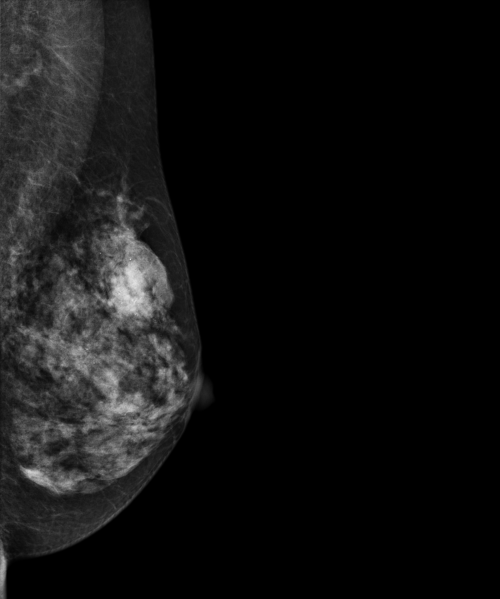

Checking test images: 100%|██████████| 748/748 [00:32<00:00, 23.33it/s]


test: 748 images verified | preview: D2-0407, R, CC, target=1


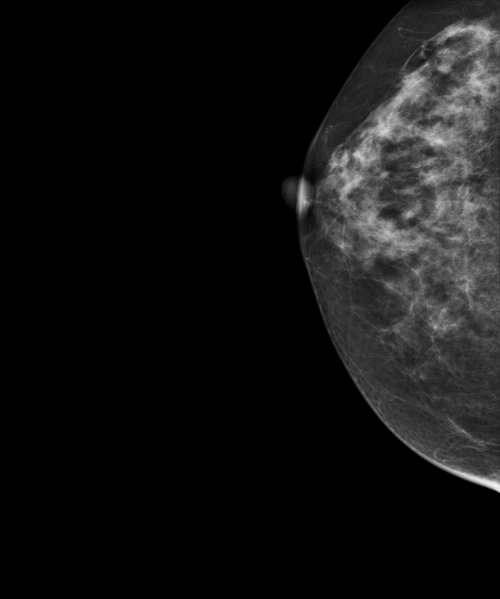

All image checks passed; 16-bit sources match the intended 8-bit conversion.


In [12]:
# @@IMAGE_SANITY@@ — Verify saved PNGs against source DICOM pixels and preview each split.
assert set(train_df["patient_id"]).isdisjoint(test_df["patient_id"]), \
    "Patient leakage between train and test"

for split, frame in (("train", train_df), ("test", test_df)):
    pd.testing.assert_frame_equal(
        frame,
        pd.read_parquet(OUT / f"{split}-metadata.parquet"),
        check_dtype=False,
        check_exact=True,
    )

    with h5py.File(RAW / f"{split}-image.hdf5", "r") as h5:
        assert frame["image_id"].is_unique
        assert set(h5.keys()) == set(frame["image_id"]), \
            f"{split}: HDF5 keys differ from metadata"
        assert h5.attrs["format"] == "png_bytes"
        assert h5.attrs["image_size"] == str((1914, 2294))

        for row in tqdm(
            frame.itertuples(index=False),
            total=len(frame),
            desc=f"Checking {split} images",
        ):
            src = pydicom.dcmread(RAW / row.dicom_path)
            assert (
                str(src.SOPInstanceUID), src.PatientID, src.ImageLaterality
            ) == (row.image_id, row.patient_id, row.laterality), \
                f"{row.image_id}: DICOM identity mismatch"

            expected = src.pixel_array
            if src.BitsStored == 16:
                expected = (
                    (expected.astype(np.uint32) + 128) // 257
                ).astype(np.uint8)

            with Image.open(io.BytesIO(h5[row.image_id][()])) as img:
                assert img.format == "PNG" and img.mode == "L"
                assert img.size == (1914, 2294)
                np.testing.assert_array_equal(
                    np.array(img),
                    expected,
                    err_msg=f"{row.image_id}: converted pixels differ",
                )

        row = frame.sample(1, random_state=42).iloc[0]
        print(
            f"{split}: {len(frame)} images verified | "
            f"preview: {row.patient_id}, {row.laterality}, "
            f"{row.view}, target={int(row.target)}"
        )
        with Image.open(io.BytesIO(h5[row.image_id][()])) as preview:
            preview.thumbnail((500, 600))
            display(preview)

print("All image checks passed; 16-bit sources match the intended 8-bit conversion.")